# 05 — Controlled model training

Train a Random Forest, LightGBM, and Decision Tree using the saved 4,000-row training partition. Compare them with the same stratified five-fold CV procedure and fold-local shared preprocessing. The held-out test partition stays untouched.

Poisonous is positive class 1. A false negative (FN) is an actually poisonous mushroom predicted edible; a false positive (FP) is an edible mushroom predicted poisonous. Missing poisonous examples is the higher-priority error here, but recall must be considered alongside precision, F1, balanced accuracy, and ROC-AUC. This is an educational exercise, not advice about real mushrooms.

## 1–2. Objectives, imports, and configuration

No hyperparameter search or threshold changes are performed. LightGBM is a required comparison: this notebook stops with an explicit dependency message if it is unavailable.

In [11]:
# Check optional LightGBM availability before importing it so the failure message
# tells the user exactly which dependency is required for this comparison.
from importlib.util import find_spec
from pathlib import Path
import json
import sys
import time

# Libraries for cross-validation, metrics, figures, and saving complete pipelines.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import dump
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
# Use the same fold definitions for scored CV, OOF predictions, and feature importance.
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import __version__ as sklearn_version

if find_spec('lightgbm') is None:
    raise ModuleNotFoundError(
        'LightGBM is required for this comparison but is not installed. '
        'Install it in the active environment with: pip install lightgbm'
    )
from lightgbm import LGBMClassifier

# Find the project root from this notebook's current directory or its parent folders.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'mushroom' / 'preprocessing.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate mushroom/preprocessing.py from the notebook directory.')
# Add the repository root only when it is not already in Python's import search path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Reuse shared preprocessing so training behavior matches the earlier project notebooks.
from mushroom.preprocessing import build_preprocessor

# Keep result files, plots, and serialized candidate models in their standard folders.
DATA_DIR = PROJECT_ROOT / 'mushroom' / 'data'
FIGURE_DIR = DATA_DIR / 'figures'
MODEL_DIR = DATA_DIR / 'models'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Record experiment-wide constants in one place for reproducibility.
TARGET = 'class'
RANDOM_STATE = 42
N_SPLITS = 5
POSITIVE_LABEL = 1
# These metrics are all evaluated with poisonous (label 1) as the positive class.
METRIC_KEYS = [
    'accuracy',
    'balanced_accuracy',
    'poisonous_precision',
    'poisonous_recall',
    'poisonous_f1',
    'roc_auc',
]
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Project: {PROJECT_ROOT}')
print(f'scikit-learn: {sklearn_version}; LightGBM: {LGBMClassifier.__module__}')

Project: /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5
scikit-learn: 1.4.2; LightGBM: lightgbm.sklearn


## 3. Load and validate the training data

Only the previously saved raw training features and labels are read. The test split is not opened. Feature groups come from the preparation metadata so the shared preprocessor is reused without duplicating transformation logic.

In [12]:
# Load the preparation metadata and saved raw training data only; the held-out test
# partition is deliberately not read in this model-development notebook.
with (DATA_DIR / 'mushroom_preprocessing_metadata.json').open(encoding='utf-8') as file:
    preprocessing_metadata = json.load(file)

X_train = pd.read_parquet(DATA_DIR / 'mushroom_X_train_raw.parquet')
y_frame = pd.read_parquet(DATA_DIR / 'mushroom_y_train.parquet')
# The saved target file should contain one label column and align row-for-row with X.
if y_frame.shape[1] != 1:
    raise ValueError(f'Expected one target column, found {y_frame.shape[1]}.')
y_train = y_frame.iloc[:, 0].rename(TARGET)

# Use recorded feature-type metadata instead of inferring types inconsistently here.
numeric_cols = preprocessing_metadata['numerical_features']
categorical_cols = preprocessing_metadata['categorical_features']
expected_features = numeric_cols + categorical_cols
# Stop if the saved feature order, target mapping, or 4,000-row training contract changed.
if X_train.columns.tolist() != expected_features:
    raise ValueError('Training feature columns/order do not match preprocessing metadata.')
if len(X_train) != len(y_train) or len(X_train) != 4000:
    raise ValueError(f'Expected 4,000 matching training rows; got X={len(X_train)}, y={len(y_train)}.')
if set(y_train.unique()) != {0, 1}:
    raise ValueError(f'Expected binary target labels {{0, 1}}, got {sorted(y_train.unique())}.')
if preprocessing_metadata['target_mapping'] != {'e': 0, 'p': 1}:
    raise ValueError('Target mapping metadata is not the required edible=0, poisonous=1.')

# Summarize dtypes and missingness without modifying any predictor values.
missing_summary = X_train.isna().sum().rename('missing_count').to_frame()
display(pd.DataFrame({
    'dtype': X_train.dtypes.astype(str),
    'missing_count': X_train.isna().sum(),
    'missing_percent': (X_train.isna().mean() * 100).round(2),
}))
# Display class counts using explicit edible/poisonous labels for readability.
display(y_train.value_counts().sort_index().rename(index={0: 'Edible (0)', 1: 'Poisonous (1)'}).to_frame('count'))
print(f'Validated X shape: {X_train.shape}; y shape: {y_train.shape}')
print(f'Numerical columns: {numeric_cols}')
print(f'Categorical columns: {categorical_cols}')
print(f'Total missing feature values: {int(missing_summary.missing_count.sum()):,}')

,dtype,missing_count,missing_percent
cap-diameter,float64,1591,39.78
stem-height,float64,820,20.50
stem-width,float64,308,7.70
spore-print-color,str,3797,94.92
gill-color,str,776,19.40
habitat,str,809,20.23
season,str,776,19.40
ring-type,str,453,11.32
cap-shape,str,323,8.08
stem-surface,str,2700,67.50


,count
class,
Edible (0),2486
Poisonous (1),1514


Validated X shape: (4000, 10); y shape: (4000,)
Numerical columns: ['cap-diameter', 'stem-height', 'stem-width']
Categorical columns: ['spore-print-color', 'gill-color', 'habitat', 'season', 'ring-type', 'cap-shape', 'stem-surface']
Total missing feature values: 12,353


## 4. Define identical preprocessing/model pipelines

Every pipeline contains a fresh shared preprocessor followed by exactly the requested classifier. The preprocessor is fitted only on each training fold during CV; models use the specified parameters and otherwise defaults.

In [13]:
# Return a complete pipeline so preprocessing is refit independently within each CV fold.
# build_preprocessor creates an unfitted transformer for the current estimator.
def make_pipeline(classifier):
    return Pipeline([
        ('preprocessor', build_preprocessor(numeric_cols, categorical_cols)),
        ('classifier', classifier),
    ])

# Configure the requested untuned candidates with fixed seeds and one worker each.
# Identical shared preprocessing is the first pipeline step for every classifier.
pipelines = {
    'Random Forest': make_pipeline(RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
    )),
    'LightGBM': make_pipeline(LGBMClassifier(
        n_estimators=200, random_state=RANDOM_STATE, verbosity=-1, n_jobs=1
    )),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
}

# Generate the fold index pairs once so every estimator and later OOF operation
# evaluates exactly the same training/validation partitions.
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(cv.split(X_train, y_train))
# Treat poisonous label 1 explicitly as positive for precision, recall, and F1.
# zero_division=0 keeps a fold with no positive predictions well-defined.
scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'poisonous_precision': make_scorer(precision_score, pos_label=POSITIVE_LABEL, zero_division=0),
    'poisonous_recall': make_scorer(recall_score, pos_label=POSITIVE_LABEL, zero_division=0),
    'poisonous_f1': make_scorer(f1_score, pos_label=POSITIVE_LABEL, zero_division=0),
    'roc_auc': 'roc_auc',
}
print('Models:', list(pipelines))
print(f'CV: {N_SPLITS}-fold stratified, shuffle=True, random_state={RANDOM_STATE}')
print('Same precomputed fold indices will be passed to every model and prediction step.')

Models: ['Random Forest', 'LightGBM', 'Decision Tree']
CV: 5-fold stratified, shuffle=True, random_state=42
Same precomputed fold indices will be passed to every model and prediction step.


## 5. Cross-validation and out-of-fold predictions

cross_validate reports fold means and sample standard deviations and also retains train scores for the overfitting check. cross_val_predict creates a prediction for each training row from a model that did not train on that row. The pooled out-of-fold confusion matrices and curves below are CV diagnostics, not final test results.

In [14]:
# Store each model's fold metrics, fitted fold estimators, and OOF predictions.
# Training scores are also requested below to support the later overfitting check.
cv_results = {}
oof_probabilities = {}
oof_predictions = {}
fit_seconds = {}

# Fit and score one candidate at a time so elapsed time can be reported per model.
for model_name, pipeline in pipelines.items():
    started = time.perf_counter()
    cv_results[model_name] = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_folds,
        scoring=scoring,
        return_train_score=True,
        return_estimator=True,
        error_score='raise',
        n_jobs=1,
    )
    # Each OOF probability is produced by a model trained without that row.
    probabilities = cross_val_predict(
        pipeline, X_train, y_train, cv=cv_folds, method='predict_proba', n_jobs=1
    )[:, 1]
    oof_probabilities[model_name] = probabilities
    # Use the default 0.50 probability threshold here; threshold tuning is reserved for notebook 06.
    oof_predictions[model_name] = (probabilities >= 0.5).astype(int)
    fit_seconds[model_name] = time.perf_counter() - started
    print(f'{model_name}: CV and out-of-fold predictions complete in {fit_seconds[model_name]:.1f}s')

result_rows = []
confusion_matrices = {}
classification_reports = {}
for model_name, result in cv_results.items():
    row = {'Model': model_name, 'cv_fit_and_prediction_seconds': fit_seconds[model_name]}
    for metric in METRIC_KEYS:
        values = result[f'test_{metric}']
        row[f'{metric}_mean'] = float(np.mean(values))
        row[f'{metric}_std'] = float(np.std(values, ddof=1))
    # Build pooled OOF confusion counts in fixed order: edible=0, poisonous=1.
    matrix = confusion_matrix(y_train, oof_predictions[model_name], labels=[0, 1])
    confusion_matrices[model_name] = matrix
    tn, fp, fn, tp = matrix.ravel()
    row.update({
        'oof_true_negative': int(tn),
        'oof_false_positive': int(fp),
        'oof_false_negative': int(fn),
        'oof_true_positive': int(tp),
        # A false negative is poisonous predicted edible; FNR is FN divided by all actual poisonous rows.
        'oof_false_negative_rate': float(fn / (fn + tp)) if fn + tp else float('nan'),
        'oof_precision': float(precision_score(y_train, oof_predictions[model_name], pos_label=1, zero_division=0)),
        'oof_recall': float(recall_score(y_train, oof_predictions[model_name], pos_label=1, zero_division=0)),
        'oof_f1': float(f1_score(y_train, oof_predictions[model_name], pos_label=1, zero_division=0)),
        'oof_roc_auc': float(roc_auc_score(y_train, oof_probabilities[model_name])),
    })
    result_rows.append(row)
    # Save a class-by-class summary from OOF labels for later readable display.
    classification_reports[model_name] = classification_report(
        y_train, oof_predictions[model_name], labels=[0, 1],
        target_names=['edible (0)', 'poisonous (1)'], zero_division=0, output_dict=True
    )

# Build the summary table after all fold and pooled OOF metrics are available.
results_df = pd.DataFrame(result_rows).set_index('Model')
display(results_df[[f'{metric}_{suffix}' for metric in METRIC_KEYS for suffix in ('mean', 'std')]])
display(results_df[['oof_false_negative', 'oof_false_negative_rate', 'oof_false_positive', 'oof_recall', 'oof_roc_auc']])
for model_name, report in classification_reports.items():
    print(f'\n{model_name} — pooled out-of-fold classification report')
    display(pd.DataFrame(report).T)

Random Forest: CV and out-of-fold predictions complete in 7.2s
LightGBM: CV and out-of-fold predictions complete in 2.1s
Decision Tree: CV and out-of-fold predictions complete in 0.5s


,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,poisonous_precision_mean,poisonous_precision_std,poisonous_recall_mean,poisonous_recall_std,poisonous_f1_mean,poisonous_f1_std,roc_auc_mean,roc_auc_std
Model,,,,,,,,,,,,
Random Forest,0.78475,0.014668,0.744456,0.017877,0.797079,0.020808,0.578618,0.033760,0.670162,0.026814,0.830382,0.015827
LightGBM,0.77675,0.012612,0.743691,0.014402,0.754977,0.021272,0.607663,0.026521,0.673105,0.020347,0.812857,0.013988
Decision Tree,0.70500,0.010117,0.683897,0.011130,0.613392,0.014006,0.597087,0.020652,0.605005,0.014833,0.683897,0.011130


,oof_false_negative,oof_false_negative_rate,oof_false_positive,oof_recall,oof_roc_auc
Model,,,,,
Random Forest,624,0.412153,229,0.587847,0.829527
LightGBM,594,0.392338,299,0.607662,0.812347
Decision Tree,610,0.402906,570,0.597094,0.683905



Random Forest — pooled out-of-fold classification report


,precision,recall,f1-score,support
edible (0),0.783409,0.907884,0.841066,2486.00000
poisonous (1),0.795353,0.587847,0.676035,1514.00000
accuracy,0.786750,0.786750,0.786750,0.78675
macro avg,0.789381,0.747865,0.758550,4000.00000
weighted avg,0.787930,0.786750,0.778602,4000.00000



LightGBM — pooled out-of-fold classification report


,precision,recall,f1-score,support
edible (0),0.786408,0.879726,0.830454,2486.00000
poisonous (1),0.754717,0.607662,0.673253,1514.00000
accuracy,0.776750,0.776750,0.776750,0.77675
macro avg,0.770562,0.743694,0.751853,4000.00000
weighted avg,0.774413,0.776750,0.770953,4000.00000



Decision Tree — pooled out-of-fold classification report


,precision,recall,f1-score,support
edible (0),0.758511,0.770716,0.764565,2486.000
poisonous (1),0.613297,0.597094,0.605087,1514.000
accuracy,0.705000,0.705000,0.705000,0.705
macro avg,0.685904,0.683905,0.684826,4000.000
weighted avg,0.703548,0.705000,0.704203,4000.000


## 6–8. Compare metrics, confusion matrices, ROC, and precision–recall

Fold-level mean±standard-deviation scores are kept distinct from pooled out-of-fold counts. FN count and FNR directly answer how often poisonous examples were missed; FP is the number of edible examples flagged poisonous. The ROC and PR curves use out-of-fold probabilities at the default 0.5 threshold is not used to make the curves; threshold tuning is deferred to notebook 06.

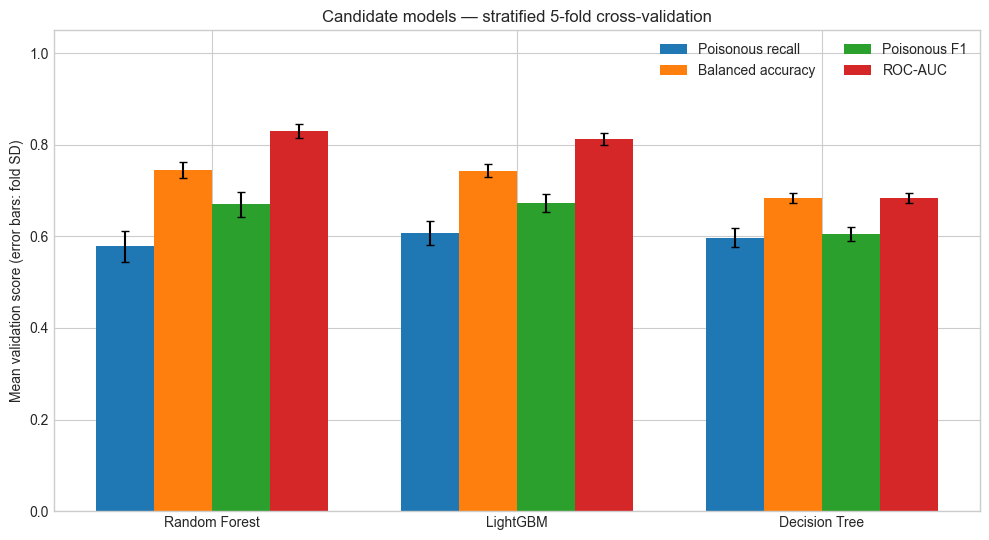

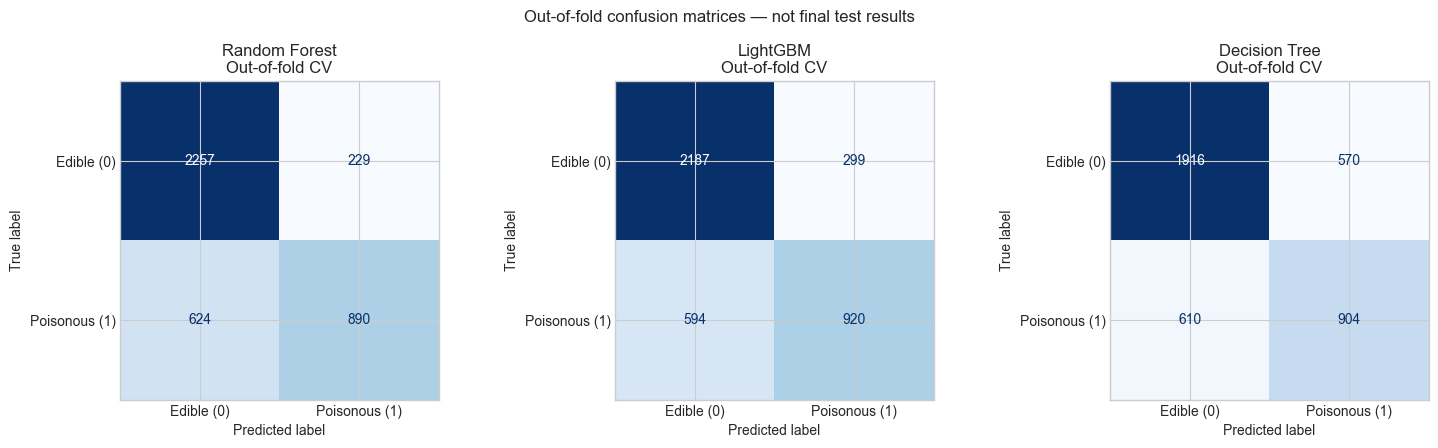

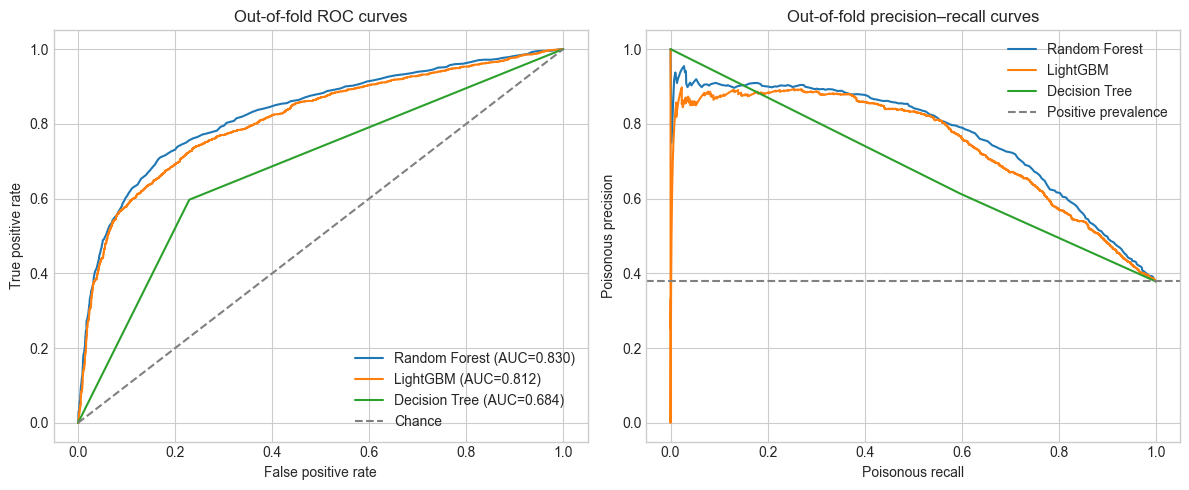

,accuracy_mean,balanced_accuracy_mean,poisonous_precision_mean,poisonous_recall_mean,poisonous_f1_mean,roc_auc_mean,oof_false_negative,oof_false_negative_rate
Model,,,,,,,,
LightGBM,0.77675,0.743691,0.754977,0.607663,0.673105,0.812857,594,0.392338
Decision Tree,0.70500,0.683897,0.613392,0.597087,0.605005,0.683897,610,0.402906
Random Forest,0.78475,0.744456,0.797079,0.578618,0.670162,0.830382,624,0.412153


In [15]:
# Show fold means with standard-deviation error bars, then save and close the figure.
# Recall, balanced accuracy, F1, and ROC-AUC together expose metric trade-offs.
# Cross-validated model metric comparison with fold standard-deviation error bars.
metric_labels = {
    'poisonous_recall': 'Poisonous recall',
    'balanced_accuracy': 'Balanced accuracy',
    'poisonous_f1': 'Poisonous F1',
    'roc_auc': 'ROC-AUC',
}
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(results_df.index))
width = 0.19
for position, (metric, label) in enumerate(metric_labels.items()):
    ax.bar(
        x + (position - 1.5) * width,
        results_df[f'{metric}_mean'],
        width,
        yerr=results_df[f'{metric}_std'],
        capsize=3,
        label=label,
    )
ax.set_xticks(x, results_df.index)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Mean validation score (error bars: fold SD)')
ax.set_title('Candidate models — stratified 5-fold cross-validation')
ax.legend(ncols=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_model_training_comparison.png', dpi=160)
# Explicitly display once and close to avoid a second inline rendering at cell completion.
plt.show()
plt.close(fig)

# These confusion matrices use out-of-fold predictions: each row was predicted by a
# model whose fold-training data excluded it. They are CV diagnostics, not test results.
fig, axes = plt.subplots(1, len(pipelines), figsize=(15, 4.5))
for ax, model_name in zip(axes, pipelines):
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrices[model_name],
        display_labels=['Edible (0)', 'Poisonous (1)'],
    ).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{model_name}\nOut-of-fold CV')
fig.suptitle('Out-of-fold confusion matrices — not final test results')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_model_training_confusion_matrices.png', dpi=160)
# Display this multi-model figure once and release its Matplotlib resources.
plt.show()
plt.close(fig)

# OOF ROC and precision-recall curves summarize performance across thresholds.
# The PR baseline equals poisonous prevalence, giving a useful reference level.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for model_name in pipelines:
    fpr, tpr, _ = roc_curve(y_train, oof_probabilities[model_name], pos_label=1)
    axes[0].plot(fpr, tpr, label=f'{model_name} (AUC={roc_auc_score(y_train, oof_probabilities[model_name]):.3f})')
    precision, recall, _ = precision_recall_curve(y_train, oof_probabilities[model_name], pos_label=1)
    axes[1].plot(recall, precision, label=model_name)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Out-of-fold ROC curves')
axes[1].axhline(y_train.mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[1].set(xlabel='Poisonous recall', ylabel='Poisonous precision', title='Out-of-fold precision–recall curves')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_model_training_roc_pr_curves.png', dpi=160)
# Display once after saving; closing prevents the notebook from showing it again.
plt.show()
plt.close(fig)

# Rank by poisonous recall for review while retaining precision, F1, balanced accuracy,
# ROC-AUC, and false-negative metrics in the displayed summary.
display(results_df[[
    'accuracy_mean', 'balanced_accuracy_mean', 'poisonous_precision_mean',
    'poisonous_recall_mean', 'poisonous_f1_mean', 'roc_auc_mean',
    'oof_false_negative', 'oof_false_negative_rate',
]].sort_values('poisonous_recall_mean', ascending=False))

## 9. Investigate overfitting

Training and validation scores are compared using the same folds. A positive train-minus-validation gap suggests potential overfitting; a small gap alone does not prove generalization, and all estimates remain dependent on this training sample.

,Model,Metric,training_mean,validation_mean,train_minus_validation
0,Random Forest,balanced_accuracy,1.000000,0.744456,0.255544
1,Random Forest,poisonous_recall,1.000000,0.578618,0.421382
2,Random Forest,roc_auc,1.000000,0.830382,0.169618
3,LightGBM,balanced_accuracy,0.942748,0.743691,0.199057
4,LightGBM,poisonous_recall,0.899273,0.607663,0.291610
5,LightGBM,roc_auc,0.994267,0.812857,0.181411
6,Decision Tree,balanced_accuracy,1.000000,0.683897,0.316103
7,Decision Tree,poisonous_recall,1.000000,0.597087,0.402913
8,Decision Tree,roc_auc,1.000000,0.683897,0.316103


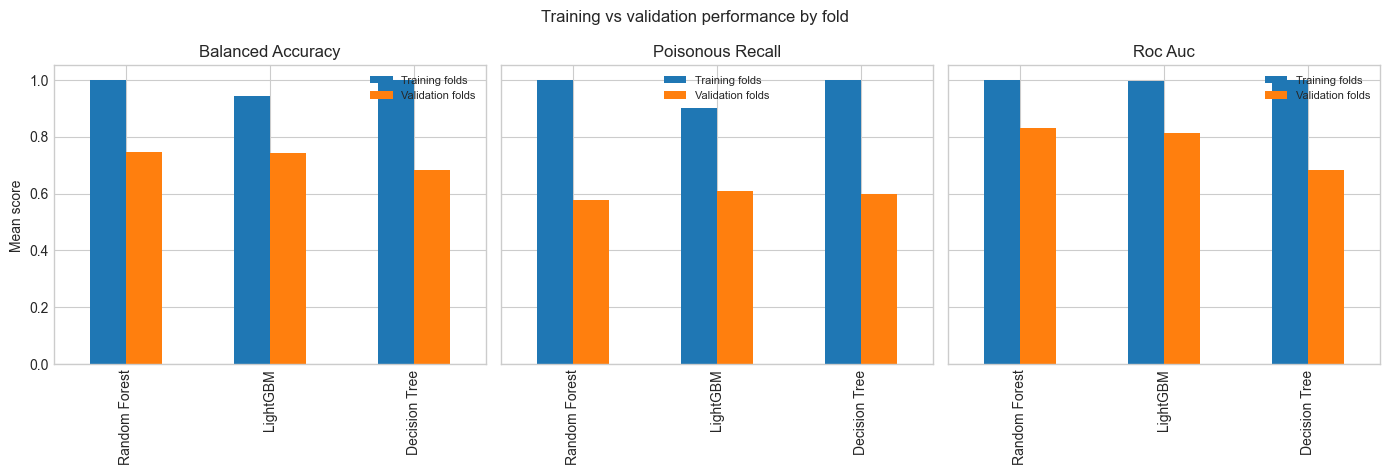

Positive gaps are warning signs, not a standalone proof of overfitting or generalization.


In [16]:
# Compare each training fold's fit score with its held-out validation-fold score.
# A large positive gap can indicate overfitting, but does not by itself prove it.
overfit_rows = []
overfit_metrics = ['balanced_accuracy', 'poisonous_recall', 'roc_auc']
for model_name, result in cv_results.items():
    for metric in overfit_metrics:
        # Aggregate across folds so the comparison uses the same CV partitions.
        train_mean = float(np.mean(result[f'train_{metric}']))
        validation_mean = float(np.mean(result[f'test_{metric}']))
        overfit_rows.append({
            'Model': model_name,
            'Metric': metric,
            'training_mean': train_mean,
            'validation_mean': validation_mean,
            'train_minus_validation': train_mean - validation_mean,
        })
overfit_df = pd.DataFrame(overfit_rows)
display(overfit_df)

# Plot the train/validation pairs for the three selected metrics on a common y scale.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for ax, metric in zip(axes, overfit_metrics):
    subset = overfit_df[overfit_df['Metric'] == metric].set_index('Model')
    subset[['training_mean', 'validation_mean']].plot(kind='bar', ax=ax, ylim=(0, 1.05))
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_ylabel('Mean score')
    ax.set_xlabel('')
    ax.legend(['Training folds', 'Validation folds'], fontsize=8)
fig.suptitle('Training vs validation performance by fold')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_model_training_overfitting.png', dpi=160)
# Show the saved figure once and close it to avoid duplicate inline rendering.
plt.show()
plt.close(fig)
print('Positive gaps are warning signs, not a standalone proof of overfitting or generalization.')

## 10. Feature importance

Tree importances are extracted from Random Forest and LightGBM after fitting the complete pipelines on all 4,000 training rows. Their transformed feature names come from the fitted preprocessor. Grouped permutation importance then permutes each original input column as one group on the corresponding held-out fold; it is an out-of-fold diagnostic, not causal evidence.

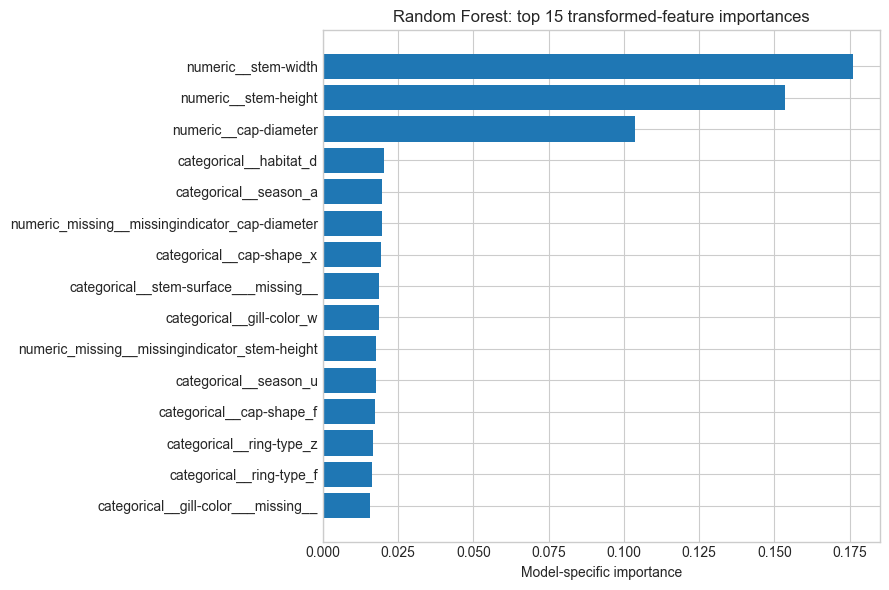

Random Forest: top 15 transformed features


,Model,transformed_feature,importance,importance_type
2,Random Forest,numeric__stem-width,0.176316,Random Forest impurity
1,Random Forest,numeric__stem-height,0.153637,Random Forest impurity
0,Random Forest,numeric__cap-diameter,0.103695,Random Forest impurity
28,Random Forest,categorical__habitat_d,0.020171,Random Forest impurity
37,Random Forest,categorical__season_a,0.019808,Random Forest impurity
3,Random Forest,numeric_missing__missingindicator_cap-diameter,0.019536,Random Forest impurity
57,Random Forest,categorical__cap-shape_x,0.019450,Random Forest impurity
58,Random Forest,categorical__stem-surface___missing__,0.018693,Random Forest impurity
25,Random Forest,categorical__gill-color_w,0.018562,Random Forest impurity
4,Random Forest,numeric_missing__missingindicator_stem-height,0.017763,Random Forest impurity


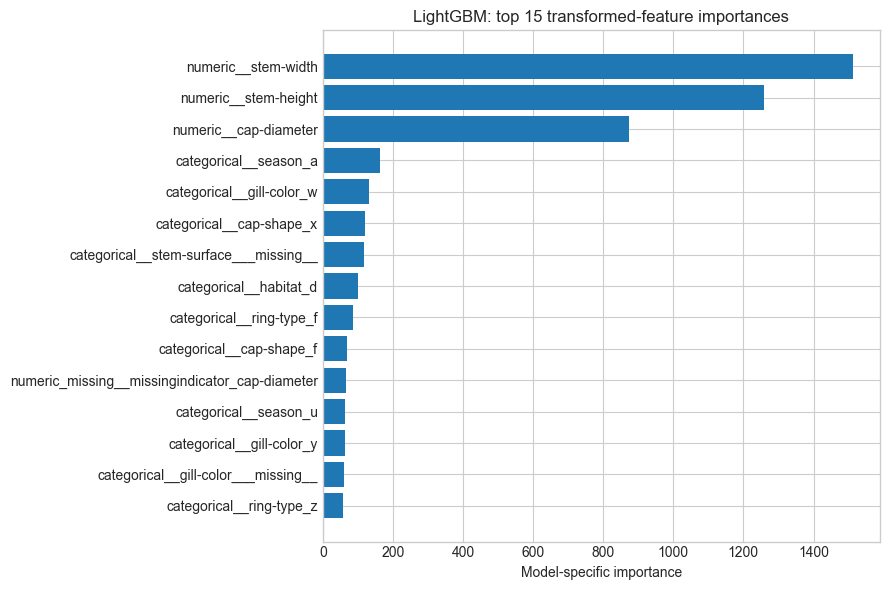

LightGBM: top 15 transformed features


,Model,transformed_feature,importance,importance_type
69,LightGBM,numeric__stem-width,1514.0,LightGBM split count
68,LightGBM,numeric__stem-height,1260.0,LightGBM split count
67,LightGBM,numeric__cap-diameter,874.0,LightGBM split count
104,LightGBM,categorical__season_a,163.0,LightGBM split count
92,LightGBM,categorical__gill-color_w,131.0,LightGBM split count
124,LightGBM,categorical__cap-shape_x,119.0,LightGBM split count
125,LightGBM,categorical__stem-surface___missing__,117.0,LightGBM split count
95,LightGBM,categorical__habitat_d,101.0,LightGBM split count
110,LightGBM,categorical__ring-type_f,87.0,LightGBM split count
120,LightGBM,categorical__cap-shape_f,68.0,LightGBM split count


,Model,original_feature,balanced_accuracy_drop_mean,balanced_accuracy_drop_std_across_folds
12,LightGBM,stem-width,0.098455,0.014491
11,LightGBM,stem-height,0.062587,0.007970
19,LightGBM,stem-surface,0.058974,0.010659
18,LightGBM,cap-shape,0.052995,0.013241
14,LightGBM,gill-color,0.032354,0.011228
17,LightGBM,ring-type,0.029412,0.009063
10,LightGBM,cap-diameter,0.021295,0.010672
15,LightGBM,habitat,0.017116,0.004344
16,LightGBM,season,0.009304,0.006350
13,LightGBM,spore-print-color,0.007281,0.003007


Tree importance is model-specific, not causal. Grouped permutation is the mean validation balanced-accuracy drop after shuffling each raw input column within its fold.


In [17]:
# Fit the full training data only after cross-validation is complete.
# These fits support candidate importance analysis, not generalization claims.
full_fitted_pipelines = {}
tree_importance_rows = []
# Built-in tree importances are computed in the transformed one-hot feature space.
for model_name in ['Random Forest', 'LightGBM']:
    fitted_pipeline = pipelines[model_name]
    fitted_pipeline.fit(X_train, y_train)
    full_fitted_pipelines[model_name] = fitted_pipeline
    # Get the fitted preprocessing step and classifier from the complete model pipeline.
    preprocessor = fitted_pipeline.named_steps['preprocessor']
    classifier = fitted_pipeline.named_steps['classifier']
    transformed_names = preprocessor.get_feature_names_out()
    importances = classifier.feature_importances_
    if len(transformed_names) != len(importances):
        raise ValueError(f'Importance/name length mismatch for {model_name}.')
    for feature, importance in zip(transformed_names, importances):
        tree_importance_rows.append({
            'Model': model_name,
            'transformed_feature': feature,
            'importance': float(importance),
            'importance_type': 'LightGBM split count' if model_name == 'LightGBM' else 'Random Forest impurity',
        })

# Collect feature names, importance scores, and their model-specific interpretation.
tree_importance_df = pd.DataFrame(tree_importance_rows)
for model_name in ['Random Forest', 'LightGBM']:
    top = (tree_importance_df[tree_importance_df['Model'] == model_name]
           .nlargest(15, 'importance').sort_values('importance'))
    # Plot the strongest transformed columns; one original category can expand into many dummies.
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top['transformed_feature'], top['importance'])
    ax.set_title(f'{model_name}: top 15 transformed-feature importances')
    ax.set_xlabel('Model-specific importance')
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'mushroom_model_training_{model_name.lower().replace(" ", "_")}_feature_importance.png', dpi=160)
    # Display this model's plot once, then close it before creating the next figure.
    plt.show()
    plt.close(fig)
    print(f'{model_name}: top 15 transformed features')
    display(top.sort_values('importance', ascending=False))

# Grouped permutation importance permutes each original input column as a whole.
# Each fold estimator is scored only on its own held-out validation rows.
permutation_rows = []
for model_name in ['Random Forest', 'LightGBM']:
    fold_importances = []
    for fold_estimator, (_, validation_indices) in zip(
        cv_results[model_name]['estimator'], cv_folds
    ):
        # A balanced-accuracy drop estimates how much that raw column helps validation performance.
        permutation = permutation_importance(
            fold_estimator,
            X_train.iloc[validation_indices],
            y_train.iloc[validation_indices],
            scoring='balanced_accuracy',
            n_repeats=5,
            random_state=RANDOM_STATE,
            n_jobs=1,
        )
        fold_importances.append(permutation.importances_mean)
    values = np.vstack(fold_importances)
    for column_index, feature in enumerate(X_train.columns):
        permutation_rows.append({
            'Model': model_name,
            'original_feature': feature,
            'balanced_accuracy_drop_mean': float(values[:, column_index].mean()),
            'balanced_accuracy_drop_std_across_folds': float(values[:, column_index].std(ddof=1)),
        })
grouped_permutation_df = pd.DataFrame(permutation_rows)
display(grouped_permutation_df.sort_values(
    ['Model', 'balanced_accuracy_drop_mean'], ascending=[True, False]
))
# Save both built-in and grouped importance tables for later analysis.
tree_importance_df.to_csv(DATA_DIR / 'mushroom_model_training_feature_importance.csv', index=False)
grouped_permutation_df.to_csv(DATA_DIR / 'mushroom_model_training_grouped_permutation_importance.csv', index=False)
print('Tree importance is model-specific, not causal. Grouped permutation is the mean validation balanced-accuracy drop after shuffling each raw input column within its fold.')

## 11. Compare against the Logistic Regression baseline

The saved baseline used the same 4,000 training observations, shared preprocessing factory, and seeded stratified five-fold CV. Thus the comparison is controlled in its data and CV procedure. Logistic Regression is a different model, but the baseline and current candidate pipelines use the same preprocessing implementation. Small differences in library versions or execution environment may still affect exact values.

In [18]:
# Load the baseline CV summary and compare it against this notebook's shared training split/folds.
baseline_path = DATA_DIR / 'mushroom_baseline_results.csv'
baseline_df = pd.read_csv(baseline_path)
# Select exactly one Logistic Regression benchmark row to avoid an ambiguous comparison.
baseline_row = baseline_df.loc[baseline_df['Model'] == 'Logistic Regression']
if len(baseline_row) != 1:
    raise ValueError('Expected exactly one Logistic Regression row in saved baseline results.')
baseline_row = baseline_row.iloc[0]

# Label the evaluation procedure explicitly; the earlier PyCaret internal split is excluded.
comparison_rows = [{
    'Model': 'Logistic Regression (notebook 03)',
    'accuracy_mean': baseline_row['accuracy_mean'],
    'balanced_accuracy_mean': baseline_row['balanced_accuracy_mean'],
    'poisonous_precision_mean': baseline_row['poisonous_precision_mean'],
    'poisonous_recall_mean': baseline_row['poisonous_recall_mean'],
    'poisonous_f1_mean': baseline_row['poisonous_f1_mean'],
    'roc_auc_mean': baseline_row['roc_auc_mean'],
    'evaluation': '5-fold CV on all 4,000 training rows',
}]
for model_name, row in results_df.iterrows():
    comparison_rows.append({
        'Model': model_name,
        **{f'{metric}_mean': row[f'{metric}_mean'] for metric in METRIC_KEYS},
        'evaluation': '5-fold CV on all 4,000 training rows',
    })
baseline_comparison_df = pd.DataFrame(comparison_rows)
display(baseline_comparison_df)
print('Baseline: accuracy=0.6960, poisonous recall=0.3474, F1=0.4633, ROC-AUC=0.6882 (approximately).')
print('PyCaret notebook 04 used an internal split and is not used as a direct numerical comparator here.')

,Model,accuracy_mean,balanced_accuracy_mean,poisonous_precision_mean,poisonous_recall_mean,poisonous_f1_mean,roc_auc_mean,evaluation
0,Logistic Regression (notebook 03),0.69600,0.627851,0.699075,0.347418,0.463269,0.688199,"5-fold CV on all 4,000 training rows"
1,Random Forest,0.78475,0.744456,0.797079,0.578618,0.670162,0.830382,"5-fold CV on all 4,000 training rows"
2,LightGBM,0.77675,0.743691,0.754977,0.607663,0.673105,0.812857,"5-fold CV on all 4,000 training rows"
3,Decision Tree,0.70500,0.683897,0.613392,0.597087,0.605005,0.683897,"5-fold CV on all 4,000 training rows"


Baseline: accuracy=0.6960, poisonous recall=0.3474, F1=0.4633, ROC-AUC=0.6882 (approximately).
PyCaret notebook 04 used an internal split and is not used as a direct numerical comparator here.


## 12. Save untuned model candidates

After CV diagnostics, save each complete preprocessing-plus-classifier pipeline fitted on all 4,000 training rows. These are candidates for subsequent controlled tuning, not final or production models.

In [19]:
# Fit Decision Tree on all training rows; RF and LightGBM were already fit above for importances.
full_fitted_pipelines['Decision Tree'] = pipelines['Decision Tree'].fit(X_train, y_train)
# Use distinct candidate filenames and save complete pipelines, including preprocessing.
model_filenames = {
    'Random Forest': 'random_forest_candidate.joblib',
    'LightGBM': 'lightgbm_candidate.joblib',
    'Decision Tree': 'decision_tree_candidate.joblib',
}
# These are untuned research candidates, not production models.
for model_name, fitted_pipeline in full_fitted_pipelines.items():
    model_path = MODEL_DIR / model_filenames[model_name]
    dump(fitted_pipeline, model_path)
    print(f'Saved {model_name}: {model_path.relative_to(PROJECT_ROOT)}')

Saved Random Forest: mushroom/data/models/random_forest_candidate.joblib
Saved LightGBM: mushroom/data/models/lightgbm_candidate.joblib
Saved Decision Tree: mushroom/data/models/decision_tree_candidate.joblib


## 13. Conclusions and next steps

The primary safety-oriented comparison is poisonous recall and the out-of-fold poisonous false-negative count/rate. Precision, F1, balanced accuracy, and ROC-AUC provide context so a trivially high-recall classifier is not rewarded without regard to usefulness. No model is declared safe or selected for deployment. In notebook 06, investigate class weights, hyperparameter search, and threshold trade-offs using CV only; preserve a separate final evaluation on the untouched test set for a later stage.

In [20]:
# Summarize metric leaders independently: recall, ROC-AUC, and pooled OOF false negatives
# answer different questions and should not be collapsed into a single winner.
highest_recall_model = results_df['poisonous_recall_mean'].idxmax()
best_auc_model = results_df['roc_auc_mean'].idxmax()
fewest_fn_model = results_df['oof_false_negative'].idxmin()
random_forest = results_df.loc['Random Forest']
print(f'Highest mean poisonous recall: {highest_recall_model} ({results_df.loc[highest_recall_model, "poisonous_recall_mean"]:.4f}).')
print(f'Best mean ROC-AUC: {best_auc_model} ({results_df.loc[best_auc_model, "roc_auc_mean"]:.4f}).')
print(f'Fewest pooled out-of-fold poisonous false negatives: {fewest_fn_model} ({int(results_df.loc[fewest_fn_model, "oof_false_negative"])} FN; FNR={results_df.loc[fewest_fn_model, "oof_false_negative_rate"]:.4f}).')
print(
    'Random Forest: '
    f'recall={random_forest["poisonous_recall_mean"]:.4f}, '
    f'precision={random_forest["poisonous_precision_mean"]:.4f}, '
    f'F1={random_forest["poisonous_f1_mean"]:.4f}, '
    f'balanced accuracy={random_forest["balanced_accuracy_mean"]:.4f}, '
    f'ROC-AUC={random_forest["roc_auc_mean"]:.4f}, '
    f'OOF FN={int(random_forest["oof_false_negative"])}.'
)
print('All three models should proceed to notebook 06 for tuned, CV-only safety/utility trade-offs; prioritize the highest-recall/fewest-FN candidates for review.')

# Persist the metric table and experiment context so later notebooks can audit the run.
results_df.to_csv(DATA_DIR / 'mushroom_model_training_results.csv')
summary = {
    'dataset': {
        'training_rows': int(len(X_train)),
        'feature_count': int(X_train.shape[1]),
        'target': TARGET,
        'target_mapping': {'0': 'edible', '1': 'poisonous'},
        'class_counts': {str(key): int(value) for key, value in y_train.value_counts().sort_index().items()},
    },
    'cross_validation': {
        'strategy': 'StratifiedKFold',
        'n_splits': N_SPLITS,
        'shuffle': True,
        'random_state': RANDOM_STATE,
        'same_fold_indices_for_all_models': True,
        'preprocessing': 'shared build_preprocessor in each sklearn Pipeline; fitted within each training fold',
    },
    'models': {
        model_name: {
            'cross_validation': {
                metric: {'mean': float(results_df.loc[model_name, f'{metric}_mean']),
                         'std': float(results_df.loc[model_name, f'{metric}_std'])}
                for metric in METRIC_KEYS
            },
            'out_of_fold': {
                'false_negatives': int(results_df.loc[model_name, 'oof_false_negative']),
                'false_negative_rate': float(results_df.loc[model_name, 'oof_false_negative_rate']),
                'false_positives': int(results_df.loc[model_name, 'oof_false_positive']),
                'recall': float(results_df.loc[model_name, 'oof_recall']),
                'roc_auc': float(results_df.loc[model_name, 'oof_roc_auc']),
            },
            'cv_fit_and_prediction_seconds': float(fit_seconds[model_name]),
            'candidate_pipeline': model_filenames[model_name],
        }
        for model_name in pipelines
    },
    'overfitting_check': overfit_df.to_dict(orient='records'),
    'baseline_comparison': {
        'baseline': 'Logistic Regression, notebook 03',
        'controlled_data_and_cv': True,
        'remaining_note': 'Shared preprocessing and seeded 5-fold CV; minor package-version differences may affect scores.',
    },
    'feature_importance': {
        'tree_importance': 'Model-specific impurity importance for Random Forest and split counts for LightGBM; not causal.',
        'grouped_permutation': 'Original input columns permuted within held-out folds; balanced accuracy drop; not causal.',
    },
    'limitations': [
        'Cross-validation uses only training data; no final test evaluation occurs in this notebook.',
        'Models are untuned candidates and no thresholds or class-balancing methods were changed.',
        'These educational results do not establish real-world mushroom safety.',
    ],
    'highest_mean_poisonous_recall': str(highest_recall_model),
    'best_mean_roc_auc': str(best_auc_model),
    'fewest_oof_false_negatives': str(fewest_fn_model),
}
# JSON contains data configuration, per-model CV/OOF results, and limitations.
with (DATA_DIR / 'mushroom_model_training_summary.json').open('w', encoding='utf-8') as file:
    json.dump(summary, file, indent=2)
print(f'Wrote CV results and run metadata under {DATA_DIR}.')

Highest mean poisonous recall: LightGBM (0.6077).
Best mean ROC-AUC: Random Forest (0.8304).
Fewest pooled out-of-fold poisonous false negatives: LightGBM (594 FN; FNR=0.3923).
Random Forest: recall=0.5786, precision=0.7971, F1=0.6702, balanced accuracy=0.7445, ROC-AUC=0.8304, OOF FN=624.
All three models should proceed to notebook 06 for tuned, CV-only safety/utility trade-offs; prioritize the highest-recall/fewest-FN candidates for review.
Wrote CV results and run metadata under /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5/mushroom/data.
